# Held-out evaluation and limitations

Use Units II, V and VI to explain these metrics. Unit VII in the uploaded syllabus covers clustering.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from src.data_preparation import load_city_data, build_features, build_targets
daily = load_city_data()


In [2]:
import json
metrics = pd.read_csv(ROOT / "results" / "metrics.csv")
summary = json.loads((ROOT / "results" / "summary.json").read_text())
print("Selected by training CV:", summary["regression_model"], summary["classification_model"])
metrics.round(4)

Selected by training CV: Lasso LogisticRegression


,task,model,mae,rmse,r2,cv_mae,alpha,cv_macro_f1,accuracy,macro_f1,roc_auc_ovr_macro
0,regression,Persistence,19.7454,29.4525,0.7209,NaN,NaN,NaN,NaN,NaN,NaN
1,regression,Linear,19.1347,27.3328,0.7596,27.4847,NaN,NaN,NaN,NaN,NaN
2,regression,Ridge,19.1682,27.3312,0.7596,27.1713,10.0,NaN,NaN,NaN,NaN
3,regression,Lasso,19.3730,27.6809,0.7534,26.4758,1.0,NaN,NaN,NaN,NaN
4,regression,RandomForestRegressor,18.9826,27.2294,0.7614,28.0497,NaN,NaN,NaN,NaN,NaN
5,classification,LogisticRegression,NaN,NaN,NaN,NaN,NaN,0.4353,0.6940,0.4886,0.8778
6,classification,DecisionTree,NaN,NaN,NaN,NaN,NaN,0.3904,0.7432,0.6446,0.9075
7,classification,RandomForestClassifier,NaN,NaN,NaN,NaN,NaN,0.4313,0.7377,0.5884,0.9185


In [3]:
reg = metrics[metrics.task == "regression"].set_index("model")
baseline_mae = reg.loc["Persistence", "mae"]
selected_mae = reg.loc[summary["regression_model"], "mae"]
print("MAE improvement over persistence (%):", (baseline_mae - selected_mae) / baseline_mae * 100)

MAE improvement over persistence (%): 1.8858783251438336


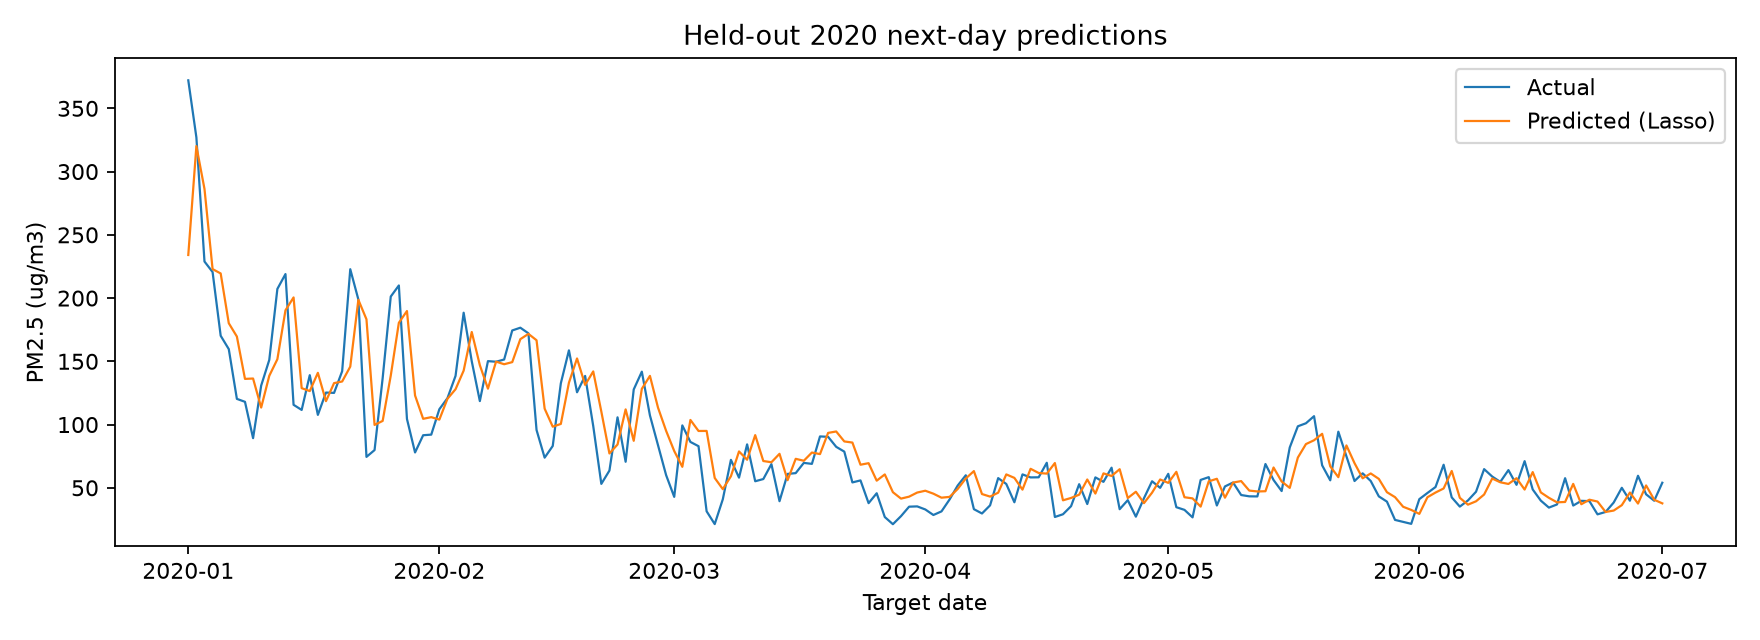

In [4]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / "results" / "figures" / "predicted_vs_actual.png")))

LogisticRegression
              precision    recall  f1-score     support
Good           0.000000  0.000000  0.000000    0.000000
Satisfactory   0.000000  0.000000  0.000000   25.000000
Moderate       0.737288  0.887755  0.805556   98.000000
Poor           0.636364  0.600000  0.617647   35.000000
Very Poor      0.653846  0.772727  0.708333   22.000000
Severe         1.000000  0.666667  0.800000    3.000000
accuracy       0.693989  0.693989  0.693989    0.693989
macro avg      0.504583  0.487858  0.488589  183.000000
weighted avg   0.611539  0.693989  0.647789  183.000000


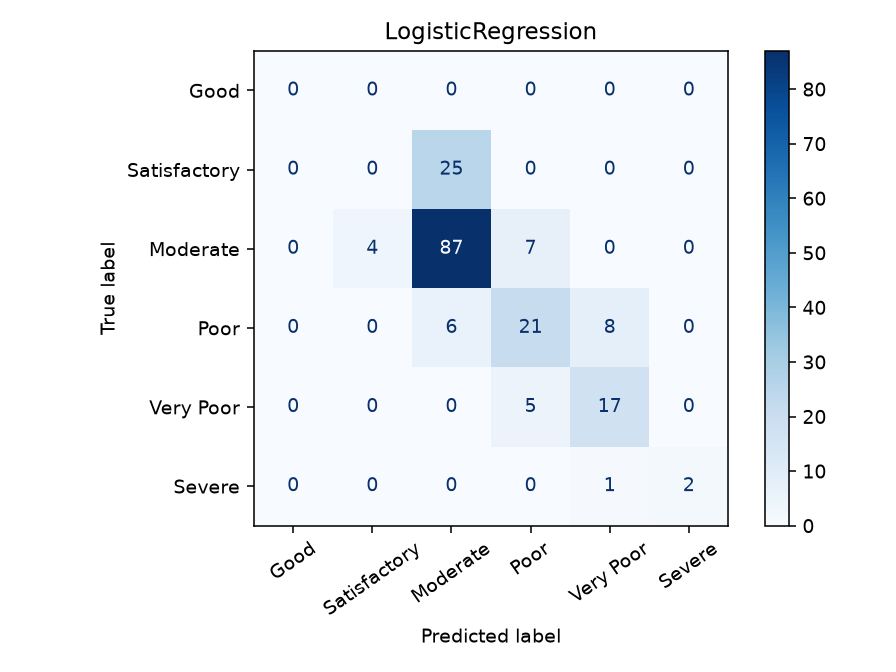

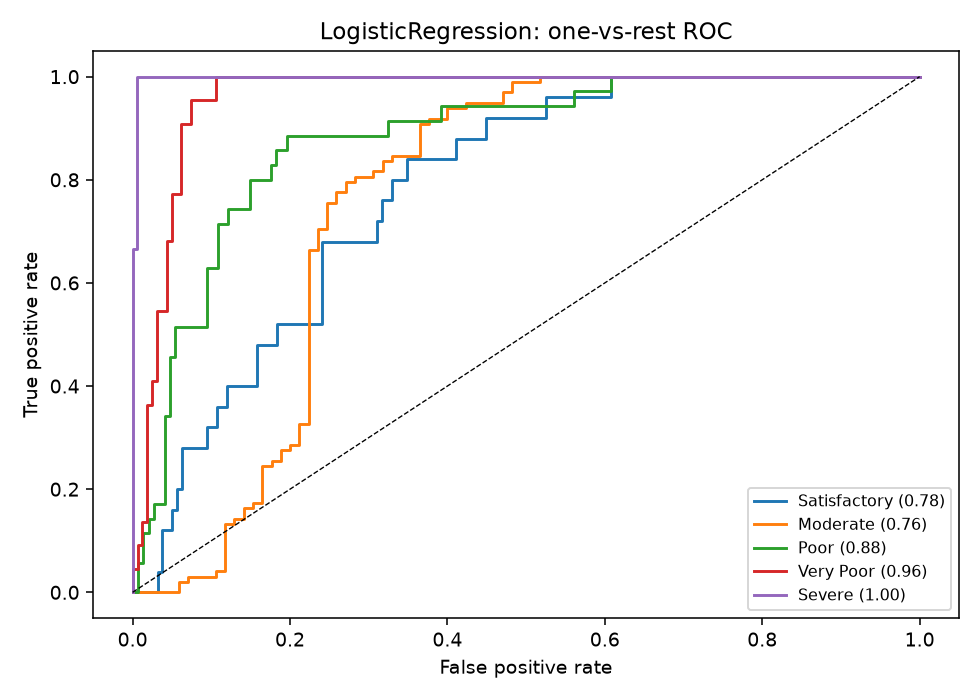

DecisionTree
              precision    recall  f1-score     support
Good           0.000000  0.000000  0.000000    0.000000
Satisfactory   0.500000  0.680000  0.576271   25.000000
Moderate       0.857143  0.734694  0.791209   98.000000
Poor           0.696970  0.657143  0.676471   35.000000
Very Poor      0.724138  0.954545  0.823529   22.000000
Severe         1.000000  1.000000  1.000000    3.000000
accuracy       0.743169  0.743169  0.743169    0.743169
macro avg      0.629708  0.671064  0.644580  183.000000
weighted avg   0.764071  0.743169  0.747210  183.000000


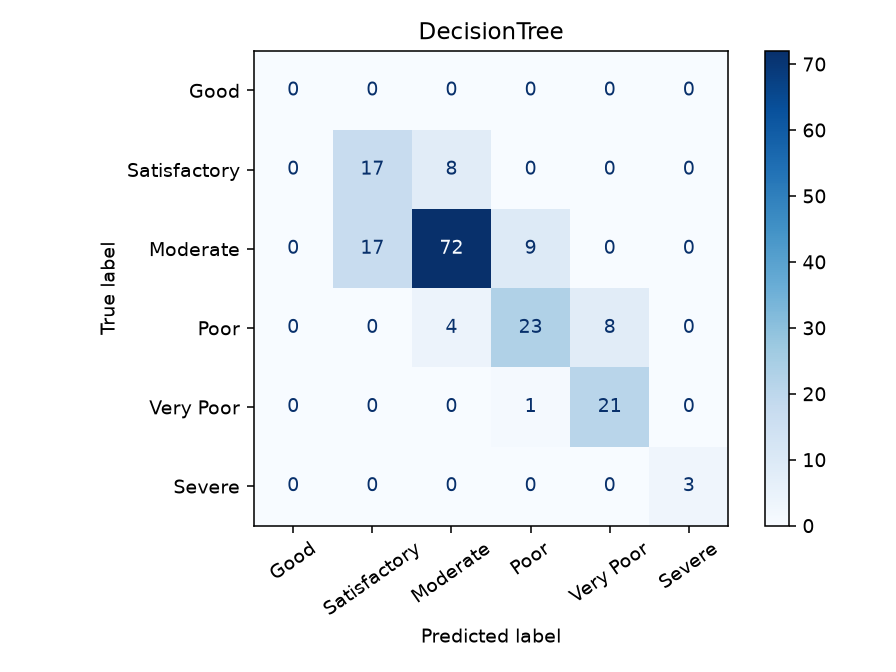

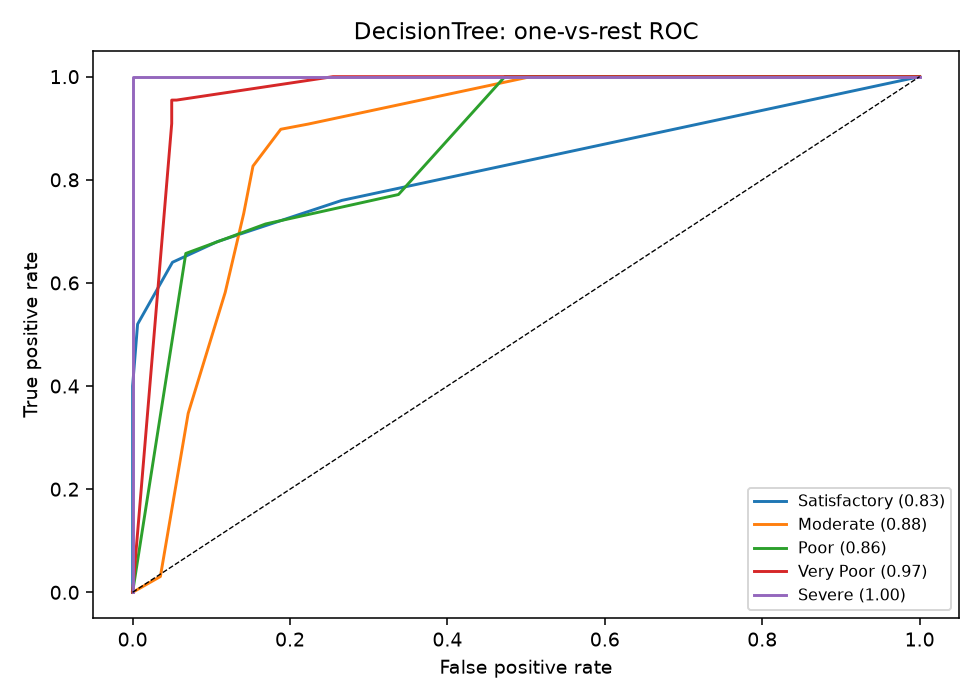

RandomForestClassifier
              precision    recall  f1-score     support
Good           0.000000  0.000000  0.000000    0.000000
Satisfactory   0.928571  0.520000  0.666667   25.000000
Moderate       0.840000  0.857143  0.848485   98.000000
Poor           0.548387  0.485714  0.515152   35.000000
Very Poor      0.529412  0.818182  0.642857   22.000000
Severe         0.750000  1.000000  0.857143    3.000000
accuracy       0.737705  0.737705  0.737705    0.737705
macro avg      0.599395  0.613506  0.588384  183.000000
weighted avg   0.757513  0.737705  0.735316  183.000000


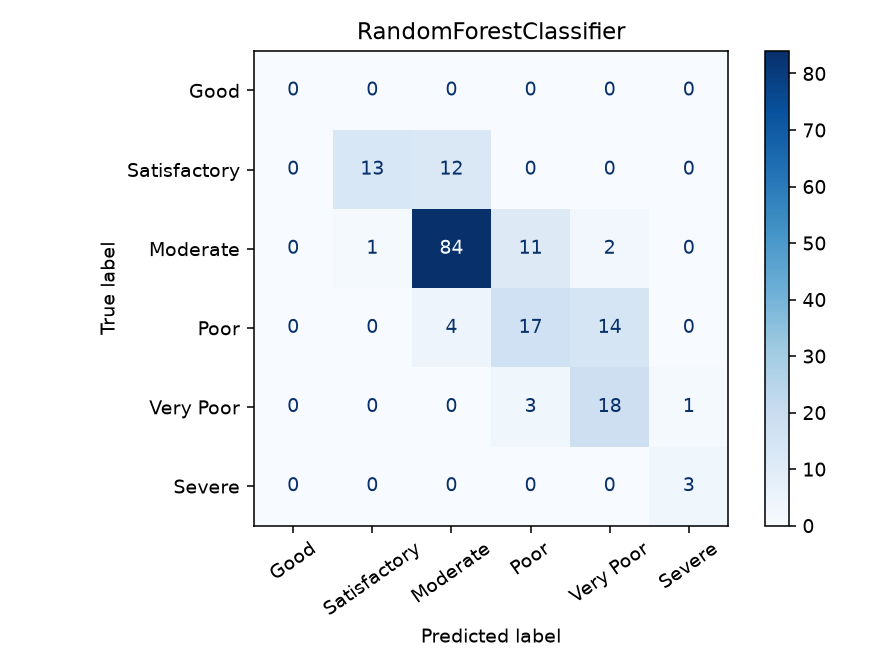

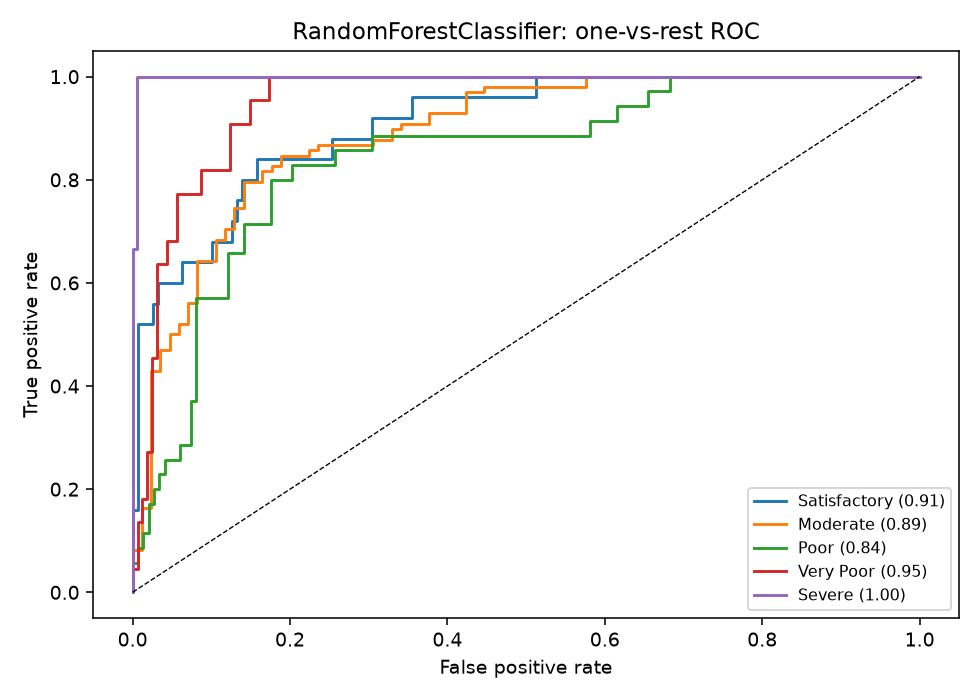

In [5]:
for model in ["LogisticRegression", "DecisionTree", "RandomForestClassifier"]:
    print(model)
    print(pd.read_csv(ROOT / "results" / f"{model}_classification_report.csv", index_col=0))
    display(Image(filename=str(ROOT / "results" / "figures" / f"{model}_confusion_matrix.png")))
    display(Image(filename=str(ROOT / "results" / "figures" / f"{model}_roc.png")))

In [6]:
pd.read_csv(ROOT / "results" / "roc_auc_by_class.csv")

,model,class,auc,status
0,LogisticRegression,Good,NaN,undefined: class absent from train or test
1,LogisticRegression,Satisfactory,0.783038,defined
2,LogisticRegression,Moderate,0.764826,defined
3,LogisticRegression,Poor,0.880309,defined
4,LogisticRegression,Very Poor,0.962451,defined
5,LogisticRegression,Severe,0.998148,defined
6,DecisionTree,Good,NaN,undefined: class absent from train or test
7,DecisionTree,Satisfactory,0.826203,defined
8,DecisionTree,Moderate,0.879532,defined
9,DecisionTree,Poor,0.863900,defined


The deployed Lasso has a modest MAE gain over persistence. Selection stays based on CV even when a different model scores better on the held-out test. The selected logistic classifier misses Satisfactory on this test, which accuracy alone hides. Good has no test examples: its ROC/AUC is undefined. Macro-F1 averages six fixed class F1 values, including zero for Good. OvR macro AUC averages the five defined class AUCs. Only three Severe examples occur in the test period. This partial-year, single-city historical evaluation cannot establish live forecasting performance. Two separately trained outputs can disagree.